# Limpieza y preparación de datos
Entrada: `dataset_simulado.csv` (8 399 filas, 13 columnas)  
Salidas: `dataset_limpio.csv` y los conjuntos `train` / `test` ya codificados y escalados.

**Hallazgos del EDA que guían este notebook**
- No hay nulos ni duplicados; los tipos de dato son correctos.
- `mora` está desbalanceada (70.4 % = 1, 29.6 % = 0) → partición estratificada.
- `atraso`: asimetría 10, máximo 245 y **3 415 casos con mora = 1 y atraso = 0** → inconsistente con `mora`.
- `ingreso`: asimétrico a la derecha (skew 2.9, máx. 30 000) → tope en p99 y versión logarítmica.
- `num_cuotas`: los "outliers" son los pagos DIARIOS (30–90 cuotas), no errores → se conservan y se crea `plazo_dias`.
- Categorías muy pequeñas: `SIN EDUCACION` (42), `SECUNDARIA` (267), `VIUDO` (189).
- `tasa_interes` tiene correlación 0.57 con `mora` (la más alta) → posible fuga de información, ver sección 9.

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RUTA_ENTRADA = "dataset_simulado.csv"
RUTA_LIMPIO = "dataset_limpio.csv"
TARGET = "mora"
SEMILLA = 42

# --- Decisiones que puedes cambiar ---
PERCENTIL_TOPE_INGRESO = 0.99          # tope superior para ingreso
EXCLUIR_DEL_MODELO = ["atraso"]        # añade "tasa_interes" si quieres evitar fuga (ver sección 9)
TAMANO_TEST = 0.20

## 1. Carga

In [2]:
df = pd.read_csv(RUTA_ENTRADA)
df_original = df.copy()          # copia para comparar antes/después
print("Forma inicial:", df.shape)

Forma inicial: (8399, 13)


## 2. Validaciones básicas

In [3]:
# Texto: quitar espacios y pasar a mayúsculas en las categóricas
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
for c in cat_cols:
    df[c] = df[c].str.strip().str.upper()

# Duplicados y nulos (el EDA no encontró, se verifica de nuevo por seguridad)
df = df.drop_duplicates().reset_index(drop=True)
print("Nulos totales:", int(df.isna().sum().sum()))

# Reglas de rango
reglas = {
    "edad entre 18 y 90": df["edad"].between(18, 90),
    "ingreso > 0": df["ingreso"] > 0,
    "atraso >= 0": df["atraso"] >= 0,
    "num_cuotas > 0": df["num_cuotas"] > 0,
    "tasa_interes > 0": df["tasa_interes"] > 0,
    "mora en {0,1}": df["mora"].isin([0, 1]),
    "exp_otras_entidades en {0,1}": df["exp_otras_entidades"].isin([0, 1]),
}
pd.Series({k: int((~v).sum()) for k, v in reglas.items()}, name="filas que incumplen")

Nulos totales: 0


edad entre 18 y 90              0
ingreso > 0                     0
atraso >= 0                     0
num_cuotas > 0                  0
tasa_interes > 0                0
mora en {0,1}                   0
exp_otras_entidades en {0,1}    0
Name: filas que incumplen, dtype: int64

## 3. Agrupar categorías con muy pocos casos

In [4]:
# nivel_educ: SIN EDUCACION (0.5 %) y SECUNDARIA (3.2 %) -> SECUNDARIA_O_MENOS
df["nivel_educ"] = df["nivel_educ"].replace({
    "SIN EDUCACION": "SECUNDARIA_O_MENOS",
    "SECUNDARIA": "SECUNDARIA_O_MENOS",
})

# estado_civil: VIUDO (2.3 %) y DIVORCIADO (6.2 %) -> DIVORCIADO_VIUDO
df["estado_civil"] = df["estado_civil"].replace({
    "DIVORCIADO": "DIVORCIADO_VIUDO",
    "VIUDO": "DIVORCIADO_VIUDO",
})

for c in ["nivel_educ", "estado_civil"]:
    print(df[c].value_counts(), "\n")

nivel_educ
UNIVERSITARIA         4802
TECNICA               3288
SECUNDARIA_O_MENOS     309
Name: count, dtype: int64 

estado_civil
CASADO              2723
CONVIVIENTE         2683
SOLTERO             2281
DIVORCIADO_VIUDO     712
Name: count, dtype: int64 



## 4. Outliers
Criterio:
- `ingreso`: valores altos plausibles pero muy extremos → **tope en el percentil 99** (winsorización) y versión logarítmica.
- `num_cuotas`: no se toca (los valores altos corresponden a pago diario).
- `edad`: se conserva (el máximo de 85 es plausible).
- `atraso`: se conserva en el dataset limpio; se decide su uso en la sección 9.

In [5]:
tope = df["ingreso"].quantile(PERCENTIL_TOPE_INGRESO)
print(f"Tope de ingreso (p{int(PERCENTIL_TOPE_INGRESO*100)}): {tope:,.2f}")
print("Filas topadas:", int((df["ingreso"] > tope).sum()))

df["ingreso_cap"] = df["ingreso"].clip(upper=tope)
df["ingreso_log"] = np.log1p(df["ingreso_cap"])

Tope de ingreso (p99): 30,000.00
Filas topadas: 0


## 5. Nuevas variables

In [6]:
# Plazo total en días: hace comparable num_cuotas entre formas de pago
dias_por_cuota = {"DIARIO": 1, "SEMANAL": 7, "QUINCENAL": 15, "MENSUAL": 30}
df["plazo_dias"] = df["num_cuotas"] * df["forma_pago"].map(dias_por_cuota)

df[["forma_pago", "num_cuotas", "plazo_dias"]].groupby("forma_pago").describe().round(1)

num_cuotas                                           plazo_dias  \
                count  mean   std   min   25%   50%   75%   max      count   
forma_pago                                                                   
DIARIO          854.0  60.7  17.7  30.0  46.0  60.0  77.0  90.0      854.0   
MENSUAL        3859.0  20.9   8.9   6.0  13.0  21.0  29.0  36.0     3859.0   
QUINCENAL      2054.0  12.0   3.7   6.0   9.0  12.0  15.0  18.0     2054.0   
SEMANAL        1632.0  16.9   5.5   8.0  12.0  17.0  22.0  26.0     1632.0   

                                                              
             mean    std    min    25%    50%    75%     max  
forma_pago                                                    
DIARIO       60.7   17.7   30.0   46.0   60.0   77.0    90.0  
MENSUAL     627.0  268.4  180.0  390.0  630.0  870.0  1080.0  
QUINCENAL   180.7   56.0   90.0  135.0  180.0  225.0   270.0  
SEMANAL     118.5   38.2   56.0   84.0  119.0  154.0   182.0

## 6. Comparación antes / después

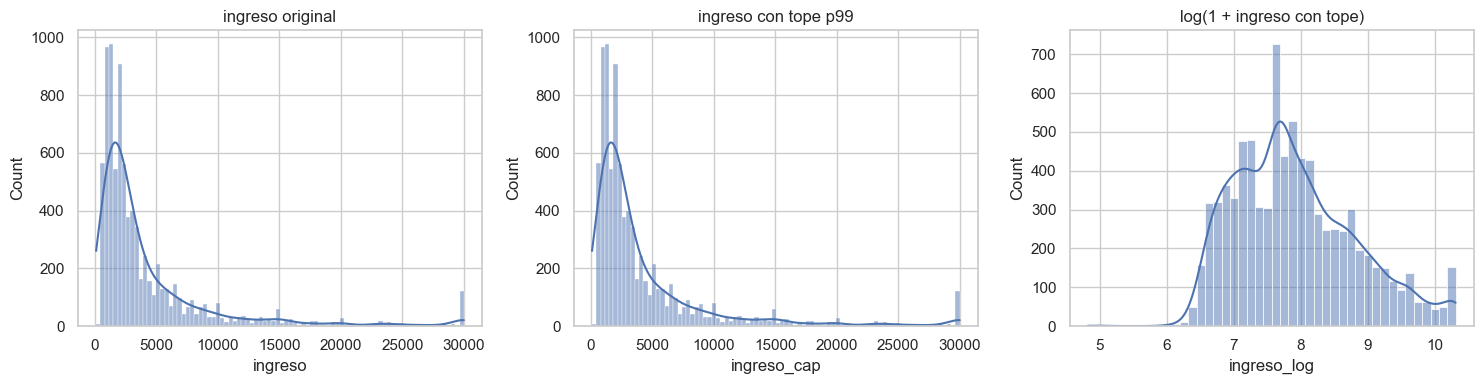

Asimetría ingreso original : 2.88
Asimetría ingreso con tope : 2.88
Asimetría ingreso log      : 0.6


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_original["ingreso"], kde=True, ax=axes[0]).set_title("ingreso original")
sns.histplot(df["ingreso_cap"], kde=True, ax=axes[1]).set_title("ingreso con tope p99")
sns.histplot(df["ingreso_log"], kde=True, ax=axes[2]).set_title("log(1 + ingreso con tope)")
plt.tight_layout()
plt.show()

print("Asimetría ingreso original :", round(df_original["ingreso"].skew(), 2))
print("Asimetría ingreso con tope :", round(df["ingreso_cap"].skew(), 2))
print("Asimetría ingreso log      :", round(df["ingreso_log"].skew(), 2))

## 7. Guardar dataset limpio

In [8]:
df.to_csv(RUTA_LIMPIO, index=False)
print("Guardado:", RUTA_LIMPIO, df.shape)
df.head()

Guardado: dataset_limpio.csv (8399, 16)


,mora,atraso,vivienda,edad,ingreso,nivel_educ,genero,estado_civil,sector_economico,exp_otras_entidades,forma_pago,num_cuotas,tasa_interes,ingreso_cap,ingreso_log,plazo_dias
0,0,235,FAMILIAR,30,3500.0,UNIVERSITARIA,F,CONVIVIENTE,EDUCATIVO,1,MENSUAL,9,18.14,3500.0,8.160804,270
1,0,18,FAMILIAR,32,900.0,TECNICA,M,CASADO,EDUCATIVO,0,SEMANAL,24,29.77,900.0,6.803505,168
2,0,0,FAMILIAR,26,2400.0,UNIVERSITARIA,F,SOLTERO,EDUCATIVO,0,MENSUAL,16,28.67,2400.0,7.783641,480
3,0,0,FAMILIAR,36,2700.0,TECNICA,F,CASADO,EDUCATIVO,0,QUINCENAL,13,38.96,2700.0,7.901377,195
4,0,0,FAMILIAR,46,3100.0,TECNICA,M,CONVIVIENTE,COMERCIO,0,MENSUAL,22,32.78,3100.0,8.039480,660


## 8. Variable objetivo y partición estratificada
`mora` tiene 70 % de unos. Se usa partición **estratificada** para que train y test conserven esa proporción.  
El escalado y la codificación se ajustan **solo con train** para evitar fuga de información.

In [9]:
y = df[TARGET]
X = df.drop(columns=[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TAMANO_TEST, stratify=y, random_state=SEMILLA
)

print("Proporción de mora (global):", round(y.mean(), 4))
print("Proporción de mora (train) :", round(y_train.mean(), 4))
print("Proporción de mora (test)  :", round(y_test.mean(), 4))
print("Train:", X_train.shape, "| Test:", X_test.shape)

Proporción de mora (global): 0.7043
Proporción de mora (train) : 0.7043
Proporción de mora (test)  : 0.7042
Train: (6719, 15) | Test: (1680, 15)


## 9. Selección de variables para el modelo
Dos advertencias:
1. **`atraso`**: hay 3 415 registros con `mora = 1` y `atraso = 0`, y su correlación con `mora` es solo 0.08. Por definición, el atraso se mide después del desembolso, así que se excluye de los predictores (configurable en `EXCLUIR_DEL_MODELO`).
2. **`tasa_interes`**: correlación 0.57 con `mora`. En este dataset simulado la tasa se generó dependiendo de `mora`, por lo que un modelo que la use tendrá un desempeño artificialmente alto. Si en tu tesis la tasa se define antes de conocer el resultado, también puedes comparar un modelo con y sin ella.

In [10]:
# Variables originales sustituidas por sus versiones transformadas
reemplazadas = ["ingreso"]
excluir = set(EXCLUIR_DEL_MODELO) | set(reemplazadas)

# Para modelar se usa ingreso_cap o ingreso_log; se deja solo ingreso_log para evitar duplicar información
excluir.add("ingreso_cap")

X_train_m = X_train.drop(columns=[c for c in excluir if c in X_train.columns])
X_test_m = X_test.drop(columns=[c for c in excluir if c in X_test.columns])

cat_model = X_train_m.select_dtypes(exclude="number").columns.tolist()
binarias = [c for c in X_train_m.columns if c in ["exp_otras_entidades"]]
num_model = [c for c in X_train_m.select_dtypes(include="number").columns if c not in binarias]

print("Categóricas:", cat_model)
print("Numéricas  :", num_model)
print("Binarias   :", binarias)

Categóricas: ['vivienda', 'nivel_educ', 'genero', 'estado_civil', 'sector_economico', 'forma_pago']
Numéricas  : ['edad', 'num_cuotas', 'tasa_interes', 'ingreso_log', 'plazo_dias']
Binarias   : ['exp_otras_entidades']


## 10. Codificación y escalado (ajustado solo con train)

In [11]:
pre = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_model),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_model),
        ("bin", "passthrough", binarias),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train_p = pre.fit_transform(X_train_m)
X_test_p = pre.transform(X_test_m)

print("Train procesado:", X_train_p.shape)
print("Test procesado :", X_test_p.shape)
X_train_p.head()

Train procesado: (6719, 25)
Test procesado : (1680, 25)


,edad,num_cuotas,tasa_interes,ingreso_log,plazo_dias,vivienda_FAMILIAR,vivienda_PROPIA,nivel_educ_TECNICA,nivel_educ_UNIVERSITARIA,genero_M,estado_civil_CONVIVIENTE,estado_civil_DIVORCIADO_VIUDO,estado_civil_SOLTERO,sector_economico_COMERCIO,sector_economico_CONSTRUCCION,sector_economico_EDUCATIVO,sector_economico_MANUFACTURA,sector_economico_OTROS,sector_economico_SALUD,sector_economico_SERVICIOS,sector_economico_TRANSPORTES,forma_pago_MENSUAL,forma_pago_QUINCENAL,forma_pago_SEMANAL,exp_otras_entidades
3919,-0.150937,0.117502,0.757903,-0.601787,1.166554,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1
3273,-0.764330,0.056134,0.972433,-0.601787,1.069400,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0
8245,-1.071027,0.608442,0.240801,0.286617,1.943787,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
2647,0.871386,-0.864379,0.919111,-0.015594,-0.387912,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
7458,-0.662098,-0.741644,0.161437,-1.381083,-0.679375,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0


In [12]:
# Verificaciones finales
assert X_train_p.isna().sum().sum() == 0 and X_test_p.isna().sum().sum() == 0
print("Medias de variables numéricas en train (≈ 0):")
print(X_train_p[num_model].mean().round(3))
print("Desv. estándar en train (≈ 1):")
print(X_train_p[num_model].std().round(3))

Medias de variables numéricas en train (≈ 0):
edad           -0.0
num_cuotas      0.0
tasa_interes    0.0
ingreso_log     0.0
plazo_dias      0.0
dtype: float64
Desv. estándar en train (≈ 1):
edad            1.0
num_cuotas      1.0
tasa_interes    1.0
ingreso_log     1.0
plazo_dias      1.0
dtype: float64


## 11. Guardar conjuntos

In [13]:
X_train_p.to_csv("X_train.csv", index=False)
X_test_p.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)
print("Archivos guardados: X_train.csv, X_test.csv, y_train.csv, y_test.csv")

Archivos guardados: X_train.csv, X_test.csv, y_train.csv, y_test.csv


## Resumen para el siguiente paso
Copia las salidas de las secciones 2, 3, 4, 8 y 10. Con eso paso a los modelos (regresión logística, árbol / random forest, etc.), manejo del desbalance (`class_weight`) y métricas adecuadas (AUC-ROC, recall, precisión, F1, matriz de confusión).